In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/bank_note_dataset.csv")

In [3]:
df.head()

,VWTI,SWTI,CWTI,EI,Class
0,2.2634,-4.4862,3.6558,-0.612510,0
1,3.2718,1.7837,2.1161,0.613340,0
2,-3.9411,-12.8792,13.0597,-3.312500,1
3,0.5195,-3.2633,3.0895,-0.984900,0
4,2.5698,-4.4076,5.9856,0.078002,0


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
VWTI,1096.0,0.448500,2.852623,-7.0364,-1.790850,0.54043,2.835350,6.5633
SWTI,1096.0,1.780643,5.922621,-13.7731,-2.125200,2.20585,6.793925,12.7302
CWTI,1096.0,1.493533,4.375655,-5.2861,-1.574975,0.67190,3.574450,17.9274
EI,1096.0,-1.157454,2.084983,-8.5482,-2.246975,-0.56919,0.399980,2.4495
Class,1096.0,0.445255,0.497221,0.0000,0.000000,0.00000,1.000000,1.0000


In [5]:
df.isnull().sum()

VWTI     0
SWTI     0
CWTI     0
EI       0
Class    0
dtype: int64

In [6]:
for col in df.columns:
    print(df[col].value_counts())

VWTI
 0.32920    4
 0.51950    3
-1.30000    3
-1.85840    3
-2.64790    3
           ..
 2.67180    1
 1.64060    1
 2.94210    1
 1.96470    1
-0.12624    1
Name: count, Length: 1072, dtype: int64
SWTI
-4.4552     6
-3.2633     4
 10.2678    3
 7.8860     3
 10.1374    3
           ..
 3.5488     1
-1.6037     1
 7.4101     1
 6.9383     1
 10.3216    1
Name: count, Length: 1021, dtype: int64
CWTI
 4.57180    5
 3.08950    4
-2.95300    3
-1.66430    3
-1.33100    3
           ..
 0.72974    1
 1.39640    1
-0.97709    1
 0.57722    1
-3.71210    1
Name: count, Length: 1028, dtype: int64
EI
-0.98880    5
-0.29570    4
 0.32110    4
-0.61251    3
-0.98490    3
           ..
-0.36424    1
 0.75558    1
-0.88406    1
 0.66377    1
-6.11850    1
Name: count, Length: 950, dtype: int64
Class
0    608
1    488
Name: count, dtype: int64


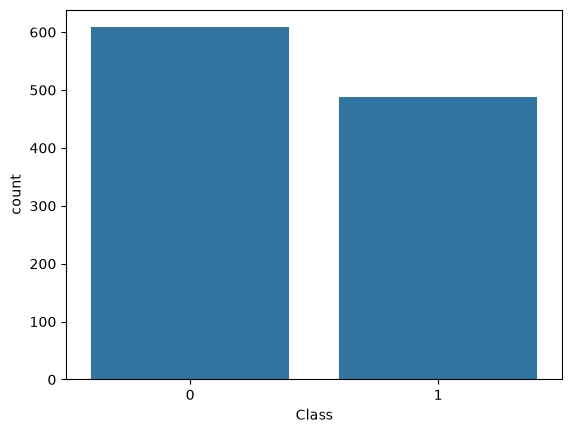

In [7]:
sns.countplot(data=df,x="Class")
plt.show()

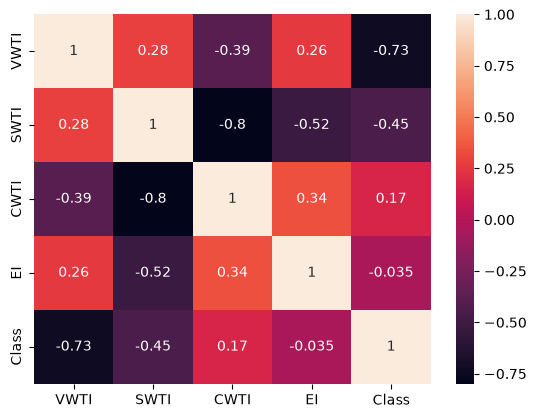

In [8]:
sns.heatmap(df.corr(),annot=True)
plt.show()

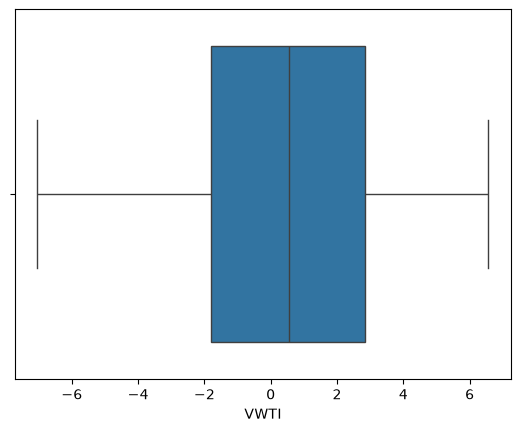

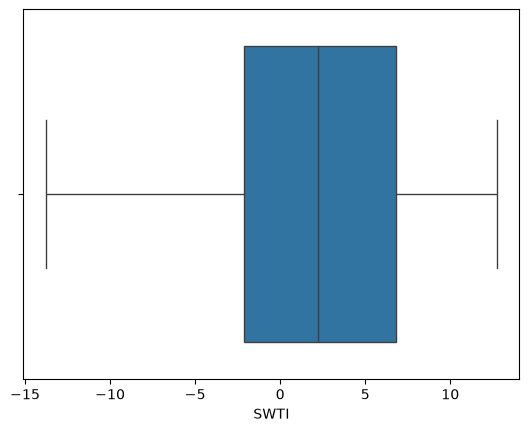

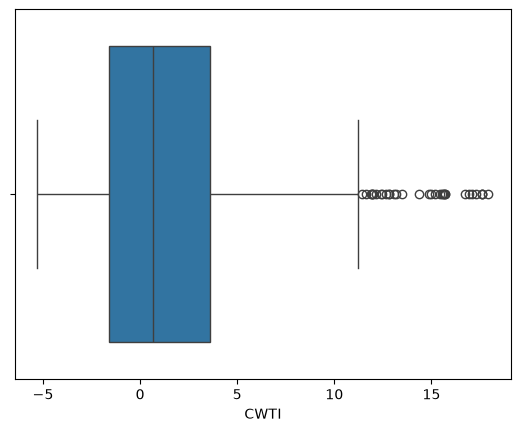

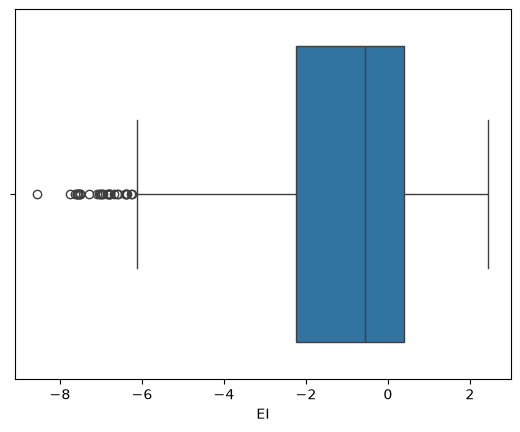

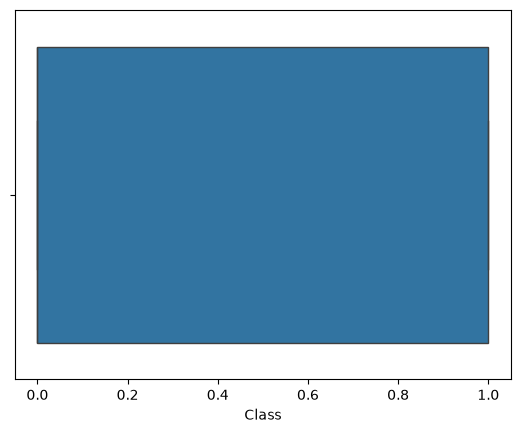

In [9]:
for col in df.columns:
    sns.boxplot(data=df,x=col)
    plt.show()

In [10]:
# Maybe swti and EI needs to clear outlier 

In [11]:
def remove_all_outliers_from_column(df,threshold=1.5):
    df_clean = df.copy()
    numeric_cols = df.select_dtypes(include=["float64","int64"]).columns

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        df_clean = df_clean[ (df_clean[col] >= lower_bound) &  (df_clean[col] <= upper_bound)]

    return df_clean.copy()

In [12]:
df_new = remove_all_outliers_from_column(df)

In [13]:
df_new.info()

<class 'pandas.DataFrame'>
Index: 1030 entries, 0 to 1095
Data columns (total 5 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   VWTI    1030 non-null   float64
 1   SWTI    1030 non-null   float64
 2   CWTI    1030 non-null   float64
 3   EI      1030 non-null   float64
 4   Class   1030 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 48.3 KB
